# Session 3b: logistic regression practice

**Course link:** Machine Learning Specialization, Course 1 Week 3. These exercises follow the Week 3 labs: the sigmoid, the logistic cost, gradient descent, the decision boundary, overfitting and regularization.

**How to use this notebook**
- Each exercise has cells with `# YOUR CODE HERE`. Write the code there, run the cell, then run the test cell after it. It prints PASS or FAIL for each check, comparing your result with scikit-learn.
- Fill in the predictions cell before each exercise.
- Stuck? The solutions are in `notes/ML03b_solutions.py` in the repo. Try first.

**Data:** the same 96 consolidation episodes (ΔCAPB ≥ 1.5 pp) and the same year-adjusted target as ML03 section 11. An episode is "weak" (1) if TFP growth from t−1 to t+2 is below the median of the other countries in the same year. Inflation is capped at ±30 %.

In [ ]:
# Load the panel straight from the GitHub repo (no upload needed)
DATA_URL = "https://raw.githubusercontent.com/penelopemichou/austerity-ml/main/data/panel_master.csv"

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

df = pd.read_csv(DATA_URL)

COUNTRY, YEAR, DCAPB, TFP = "country", "year", "dcapb_main", "tfp"
H, CAP = 2, 30
CONTROLS_RAW = ["gdp_growth", "debt_gdp", "inflation", "trade_open"]
CONTROLS = [c + "_lag1" for c in CONTROLS_RAW]
INPUTS = [DCAPB] + CONTROLS
INFL = "inflation_lag1"

def add_columns(frame, cap=CAP):
    d = frame.sort_values([COUNTRY, YEAR]).copy()
    d["inflation"] = d["inflation"].clip(-cap, cap)
    d["log_tfp"] = np.log(d[TFP])
    d["growth"] = 100 * (d.groupby(COUNTRY)["log_tfp"].shift(-H) - d.groupby(COUNTRY)["log_tfp"].shift(1))
    for raw, lagged in zip(CONTROLS_RAW, CONTROLS):
        d[lagged] = d.groupby(COUNTRY)[raw].shift(1)
    return d[[COUNTRY, YEAR, DCAPB, "growth"] + CONTROLS].dropna().reset_index(drop=True)

rows = add_columns(df)

def make_split(hidden):
    # Year-adjusted target, as in ML03 section 11: the yearly medians come from the training countries only
    tr_all = rows[~rows[COUNTRY].isin(hidden)]
    median = tr_all.groupby(YEAR)["growth"].median()
    tr = tr_all[tr_all[DCAPB] >= 1.5].copy()
    te = rows[rows[COUNTRY].isin(hidden) & (rows[DCAPB] >= 1.5)].copy()
    for d in (tr, te):
        d["weak"] = (d["growth"] < d[YEAR].map(median)).astype(float)
    return tr, te

episodes, _ = make_split([])                  # all 96 episodes, medians from all 26 countries
TEST_COUNTRIES = ["Belgium", "Greece", "Lithuania", "Malta", "Slovakia", "Spain"]   # same six as ML01-ML03 (seed 42)
print(f"{len(episodes)} episodes in {episodes[COUNTRY].nunique()} countries, share weak {episodes['weak'].mean():.2f}")

def check(name, test):
    # Runs one test and prints PASS or FAIL, without stopping the notebook
    try:
        ok = bool(test())
    except Exception as e:
        print(f"FAIL  {name}  ({type(e).__name__}: {e})")
        return
    print(("PASS  " if ok else "FAIL  ") + name)

96 episodes in 24 countries, share weak 0.52


## Exercise 1: the sigmoid, the cost, the gradient and gradient descent

**Course link:** Week 3 videos *Logistic regression*, *Cost function for logistic regression*, *Simplified cost function*, *Gradient descent implementation* and *Regularized logistic regression*.

**In plain English**
- Linear regression gives any number. For a yes/no question we want a chance between 0 and 1. The **sigmoid** g(z) = 1 / (1 + e⁻ᶻ) squeezes any z into that range, and the model is f(x) = g(w·x + b).
- The **cost** is the average log loss: −y·log(f) − (1 − y)·log(1 − f) for each episode. Being confident and wrong costs a lot. With **regularization**, add λ/(2m)·Σw² (b is not regularized). Tip: clip f to [1e-15, 1 − 1e-15] so log(0) never happens.
- The **gradient** looks just like linear regression's: dj_dw = (1/m)·Σ(f − y)·x + (λ/m)·w and dj_db = (1/m)·Σ(f − y). The only difference is that f now goes through the sigmoid.
- **Gradient descent** repeats: compute the gradient, step w and b downhill by α times the gradient, and record the cost.

The inputs are ΔCAPB and the four lagged controls, z-scored over all 96 episodes. This exercise is about the mechanics, so there is no hidden-country test here.

My predictions (fill these in before running)

1. The cost with w = 0 and b = 0 (every chance is 50 %) will be about:
2. After training, will the cost be far below that number, or only a little below?
3. Which of the five inputs will get the largest weight (in absolute value)?

In [ ]:
X = episodes[INPUTS].to_numpy()
X = (X - X.mean(axis=0)) / X.std(axis=0)   # z-scores
y = episodes["weak"].to_numpy()
print("X:", X.shape, " y:", y.shape)

X: (96, 5)  y: (96,)


In [ ]:
def sigmoid(z):
    """The sigmoid g(z) = 1 / (1 + e^(-z)). Works on a number or a whole array."""
    # YOUR CODE HERE
    g = 1 / (1 + np.exp(-z))
    return g

In [ ]:
def compute_cost_logistic(X, y, w, b, lambda_=0.0):
    """Logistic cost: average log loss plus the regularization term λ/(2m)·Σw²."""
    m, n = X.shape
    # YOUR CODE HERE
    z = X @ w + b                        # w·x + b for every episode at once
    f = sigmoid(z)                       # the model's chance of "weak", between 0 and 1
    f = np.clip(f, 1e-15, 1 - 1e-15)     # keeps log() away from exactly 0

    loss = -y * np.log(f) - (1 - y) * np.log(1 - f)    # YOUR LINE: −y·log(f) − (1−y)·log(1−f)
    cost = np.mean(loss)                 # average over the m episodes

    reg = lambda_ / (2 * m) * np.sum(w ** 2)                  # YOUR LINE: λ/(2m) · Σw²
    total_cost = cost + reg
    return total_cost

In [ ]:
def compute_gradient_logistic(X, y, w, b, lambda_=0.0):
    """Gradient of the cost. Returns dj_db, dj_dw (the same order as the course labs)."""
    m, n = X.shape
    err = sigmoid(X @ w + b) - y                      # how wrong each prediction is
    dj_dw = (X.T @ err) / m + (lambda_ / m) * w       # b is not regularized
    dj_db = np.mean(err)
    return dj_db, dj_dw

In [ ]:
def gradient_descent(X, y, w_in, b_in, alpha, num_iters, lambda_=0.0):
    """Repeat: compute the gradient, take a step of size alpha, record the cost."""
    w, b = w_in.copy(), b_in
    J_history = []
    for i in range(num_iters):
        dj_db, dj_dw = compute_gradient_logistic(X, y, w, b, lambda_)   # which way is downhill
        w = w - alpha * dj_dw                                           # step downhill
        b = b - alpha * dj_db
        J_history.append(compute_cost_logistic(X, y, w, b, lambda_))    # record the cost
    return w, b, J_history

In [ ]:
# Test exercise 1. scikit-learn's C equals 1/λ in the course's version of the cost, so C = 1 means λ = 1
sk = LogisticRegression(C=1.0, max_iter=10000, tol=1e-10).fit(X, y)
w_sk, b_sk = sk.coef_[0], sk.intercept_[0]
p_sk = sk.predict_proba(X)[:, 1]
m = len(y)

check("sigmoid(0) = 0.5", lambda: np.isclose(sigmoid(0), 0.5))
check("sigmoid matches scikit-learn's predicted chances", lambda: np.allclose(sigmoid(X @ w_sk + b_sk), p_sk))
check("cost with w = 0 matches scikit-learn's log loss for a 50 % guess",
      lambda: np.isclose(compute_cost_logistic(X, y, np.zeros(5), 0.0), log_loss(y, np.full(m, 0.5))))
check("cost with λ = 0 matches scikit-learn's log loss",
      lambda: np.isclose(compute_cost_logistic(X, y, w_sk, b_sk, 0.0), log_loss(y, p_sk)))
check("cost with λ = 1 adds λ/(2m)·Σw²",
      lambda: np.isclose(compute_cost_logistic(X, y, w_sk, b_sk, 1.0), log_loss(y, p_sk) + np.sum(w_sk ** 2) / (2 * m)))

def numerical_gradient(lambda_, h=1e-6):
    # Nudge each weight a little and watch scikit-learn's log loss change (no λ term when lambda_ = 0)
    def J(w, b):
        p = 1 / (1 + np.exp(-(X @ w + b)))
        return log_loss(y, p) + lambda_ / (2 * m) * np.sum(w ** 2)
    w0, g = np.full(5, 0.1), np.zeros(5)
    for j in range(5):
        e = np.zeros(5); e[j] = h
        g[j] = (J(w0 + e, 0.1) - J(w0 - e, 0.1)) / (2 * h)
    return (J(w0, 0.1 + h) - J(w0, 0.1 - h)) / (2 * h), g, w0

def gradient_matches(lambda_):
    db_num, dw_num, w0 = numerical_gradient(lambda_)
    dj_db, dj_dw = compute_gradient_logistic(X, y, w0, 0.1, lambda_)
    return np.isclose(dj_db, db_num, atol=1e-6) and np.allclose(dj_dw, dw_num, atol=1e-6)

check("gradient (λ = 0) matches the slope of scikit-learn's log loss", lambda: gradient_matches(0.0))
check("gradient (λ = 1) matches the slope of scikit-learn's log loss", lambda: gradient_matches(1.0))
check("gradient is zero at scikit-learn's solution (λ = 1)",
      lambda: max(abs(compute_gradient_logistic(X, y, w_sk, b_sk, 1.0)[0]),
                  np.abs(compute_gradient_logistic(X, y, w_sk, b_sk, 1.0)[1]).max()) < 1e-5)

w_gd, b_gd, J_hist = None, None, None
def run_gd():
    global w_gd, b_gd, J_hist
    w_gd, b_gd, J_hist = gradient_descent(X, y, np.zeros(5), 0.0, alpha=1.0, num_iters=3000, lambda_=1.0)
    return np.allclose(np.r_[w_gd, b_gd], np.r_[w_sk, b_sk], atol=1e-4)
check("gradient descent (α = 1, 3000 steps, λ = 1) finds scikit-learn's weights", run_gd)
check("the cost falls at every step", lambda: len(J_hist) == 3000 and np.all(np.diff(J_hist) <= 1e-12))

PASS  sigmoid(0) = 0.5
PASS  sigmoid matches scikit-learn's predicted chances
PASS  cost with w = 0 matches scikit-learn's log loss for a 50 % guess
PASS  cost with λ = 0 matches scikit-learn's log loss
PASS  cost with λ = 1 adds λ/(2m)·Σw²
PASS  gradient (λ = 0) matches the slope of scikit-learn's log loss
PASS  gradient (λ = 1) matches the slope of scikit-learn's log loss
PASS  gradient is zero at scikit-learn's solution (λ = 1)
PASS  gradient descent (α = 1, 3000 steps, λ = 1) finds scikit-learn's weights
PASS  the cost falls at every step


                 your weights  scikit-learn
b                      0.1244        0.1244
dcapb_main             0.1922        0.1922
gdp_growth_lag1       -0.2358       -0.2358
debt_gdp_lag1          0.5122        0.5122
inflation_lag1         0.3767        0.3767
trade_open_lag1       -0.1395       -0.1395


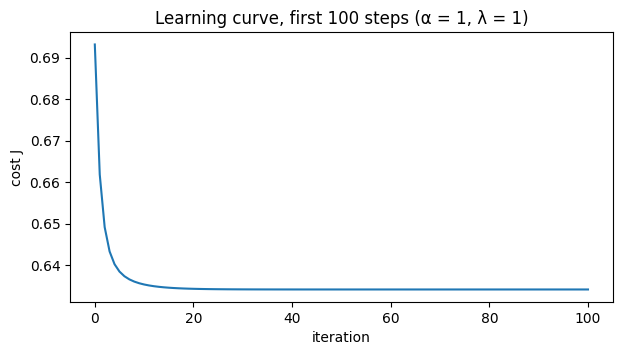

Cost at the start: 0.6931, at the end: 0.6341


In [ ]:
# Look at your result (runs once all the tests pass)
print(pd.DataFrame({"your weights": np.r_[b_gd, w_gd], "scikit-learn": np.r_[b_sk, w_sk]},
                   index=["b"] + INPUTS).round(4))
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot([compute_cost_logistic(X, y, np.zeros(5), 0.0, 1.0)] + J_hist[:100])
ax.set_title("Learning curve, first 100 steps (α = 1, λ = 1)")
ax.set_xlabel("iteration"); ax.set_ylabel("cost J"); plt.show()
print(f"Cost at the start: {compute_cost_logistic(X, y, np.zeros(5), 0.0, 1.0):.4f}, at the end: {J_hist[-1]:.4f}")

**Compare with your predictions.** Why is the starting cost exactly log(2)? And how much lower is the final cost: does the model know much more than a 50/50 guess?

## Exercise 2: the decision boundary with two inputs

**Course link:** Week 3 video *Decision boundary* and the optional lab on it.

**In plain English**
- The model says "weak" when its chance is at least 50 %. That happens exactly when w·x + b ≥ 0, because g(0) = 0.5.
- With two inputs, the points where w₁·ΔCAPB + w₂·inflation + b = 0 form a straight line: the **decision boundary**. On one side the model says "weak", on the other "not weak".
- Solving for inflation gives the line: inflation = −(b + w₁·ΔCAPB) / w₂.

You fit the model on z-scores with your own gradient descent (λ = 0). The weights are then converted back to original units, so the line can be drawn on the real axes.

My predictions (fill these in before running)

1. Will the boundary slope up or down? In other words, does more tightening need more or less inflation before the model says "weak"?
2. Roughly what share of the 96 episodes will be on the wrong side of the line:
3. Will the two groups look clearly separated in the chart, or mixed up?

In [ ]:
X2 = episodes[[DCAPB, INFL]].to_numpy()
mu2, sigma2 = X2.mean(axis=0), X2.std(axis=0)
w2_s, b2_s, _ = gradient_descent((X2 - mu2) / sigma2, y, np.zeros(2), 0.0, alpha=1.0, num_iters=3000, lambda_=0.0)

def to_original_units(w_scaled, b_scaled, mu, sigma):
    w = w_scaled / sigma
    return w, b_scaled - np.sum(w * mu)

w2, b2 = to_original_units(w2_s, b2_s, mu2, sigma2)
print(f"Weights in original units: ΔCAPB {w2[0]:.4f}, inflation {w2[1]:.4f}, b {b2:.4f}")

Weights in original units: ΔCAPB 0.1473, inflation 0.0617, b -0.5952


In [ ]:
def boundary_inflation(dcapb, w, b):
    """Inflation on the decision boundary for each ΔCAPB value."""
    # The boundary is where w[0]·ΔCAPB + w[1]·inflation + b = 0 (a 50 % chance)
    inflation = -(b + w[0] * dcapb) / w[1]
    return inflation

In [ ]:
def plot_decision_boundary(data, w, b):
    """Scatter the episodes (weak / not weak) and draw the boundary line. Returns the axes."""
    fig, ax = plt.subplots(figsize=(8, 5))
    weak = data["weak"] == 1
    ax.scatter(data.loc[~weak, DCAPB], data.loc[~weak, INFL], marker="o", label="not weak", alpha=0.7)
    ax.scatter(data.loc[weak, DCAPB], data.loc[weak, INFL], marker="x", label="weak", alpha=0.9)
    xs = np.linspace(data[DCAPB].min(), data[DCAPB].max(), 100)
    ax.plot(xs, boundary_inflation(xs, w, b), color="black", label="decision boundary (50 %)")
    ax.set_ylim(data[INFL].min() - 3, data[INFL].max() + 3)   # keep the view on the episodes
    ax.set_xlabel("ΔCAPB at t (pp of GDP)")
    ax.set_ylabel("inflation at t−1 (%, capped at ±30)")
    ax.legend()
    return ax

PASS  your weights (original units) match scikit-learn
PASS  points on your line get a 50 % chance from scikit-learn
PASS  plot_decision_boundary runs and returns the axes
PASS  the chart has two groups of points
PASS  the chart has a line, and it is the decision boundary
PASS  both axes have labels


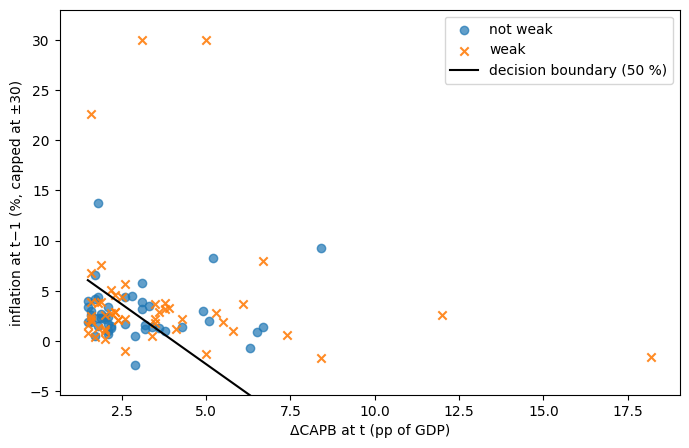

In [ ]:
# Test exercise 2
sk2 = LogisticRegression(penalty=None, max_iter=10000, tol=1e-10).fit(X2, y)
w_sk2, b_sk2 = sk2.coef_[0], sk2.intercept_[0]
xs_test = np.array([1.5, 3.0, 6.0])

check("your weights (original units) match scikit-learn", lambda: np.allclose(np.r_[w2, b2], np.r_[w_sk2, b_sk2], atol=1e-4))
check("points on your line get a 50 % chance from scikit-learn",
      lambda: np.allclose(sk2.predict_proba(np.column_stack([xs_test, boundary_inflation(xs_test, w_sk2, b_sk2)]))[:, 1], 0.5))

ax = None
def run_plot():
    global ax
    ax = plot_decision_boundary(episodes, w2, b2)
    return ax is not None
check("plot_decision_boundary runs and returns the axes", run_plot)
check("the chart has two groups of points", lambda: len(ax.collections) == 2)
check("the chart has a line, and it is the decision boundary",
      lambda: any(np.allclose(l.get_ydata(), -(b_sk2 + w_sk2[0] * np.asarray(l.get_xdata())) / w_sk2[1], atol=1e-3)
                  for l in ax.get_lines()))
check("both axes have labels", lambda: ax.get_xlabel() != "" and ax.get_ylabel() != "")
plt.show()

In [ ]:
# How many episodes does the line get right?
pred = (X2 @ w2 + b2 >= 0).astype(float)
print(f"Accuracy on all 96 episodes (the same data it was fitted on): {np.mean(pred == y):.2f}; "
      f"always saying 'weak': {np.mean(y == 1):.2f}")

Accuracy on all 96 episodes (the same data it was fitted on): 0.58; always saying 'weak': 0.52


**Compare with your predictions.** Notice that this accuracy is measured on the same episodes the line was fitted on. Exercise 3 shows why that flatters a model.

## Exercise 3: overfitting, and how λ fixes it

**Course link:** Week 3 videos *The problem of overfitting*, *Addressing overfitting* and *Cost function with regularization*, and the optional lab *Overfitting*.

**In plain English**
- Adding powers of one input (x, x², …, x⁶) lets the model draw a wiggly curve instead of a straight cut. With only 71 training episodes, a wiggly curve can follow the noise in the training countries and then fail on new ones: **overfitting**.
- **Regularization** (λ) penalizes big weights, which keeps the curve smoother. Too much λ and the model learns nothing (**underfitting**).
- To see overfitting, compare the log loss on the **training countries** with the log loss on the **hidden countries**. These are the same six as ML03 (Belgium, Greece, Lithuania, Malta, Slovakia, Spain).
- The powers are z-scored with the mean and spread of the **training countries only**, so nothing about the hidden countries leaks in.

My predictions (fill these in before running)

1. As λ goes from 0 to 100, will the training log loss go up or down? And the hidden-country log loss?
2. Which λ will give the lowest hidden-country log loss (0 / 0.1 / 1 / 10 / 100)?
3. Will any λ beat the simple guess (the training share of "weak" for every episode) on the hidden countries?

In [ ]:
train, test = make_split(TEST_COUNTRIES)      # yearly medians from the 20 training countries only
y_train, y_test = train["weak"].to_numpy(), test["weak"].to_numpy()
print(f"Training episodes: {len(train)}, hidden-country episodes: {len(test)}")

Training episodes: 71, hidden-country episodes: 25


In [ ]:
def poly_features(x, degree):
    """Columns x, x², ..., x^degree for a 1-D array x."""
    X_poly = np.column_stack([x ** d for d in range(1, degree + 1)])
    return X_poly

def fit_zscore(X):
    """Mean and standard deviation of every column (like scikit-learn's StandardScaler)."""
    mu = X.mean(axis=0)
    sigma = X.std(axis=0)
    return mu, sigma

def zscore(X, mu, sigma):
    return (X - mu) / sigma

In [ ]:
# Test exercise 3, part 1
x_tr = train[DCAPB].to_numpy()
check("poly_features matches scikit-learn's PolynomialFeatures",
      lambda: np.allclose(poly_features(x_tr, 6), PolynomialFeatures(6, include_bias=False).fit_transform(x_tr.reshape(-1, 1))))
scaler = StandardScaler().fit(PolynomialFeatures(6, include_bias=False).fit_transform(x_tr.reshape(-1, 1)))
check("fit_zscore matches scikit-learn's StandardScaler",
      lambda: np.allclose(fit_zscore(poly_features(x_tr, 6))[0], scaler.mean_) and np.allclose(fit_zscore(poly_features(x_tr, 6))[1], scaler.scale_))
check("zscore of the hidden countries uses the training mean and spread",
      lambda: np.allclose(zscore(poly_features(test[DCAPB].to_numpy(), 6), scaler.mean_, scaler.scale_),
                          scaler.transform(PolynomialFeatures(6, include_bias=False).fit_transform(test[DCAPB].to_numpy().reshape(-1, 1)))))

PASS  poly_features matches scikit-learn's PolynomialFeatures
PASS  fit_zscore matches scikit-learn's StandardScaler
PASS  zscore of the hidden countries uses the training mean and spread


In [ ]:
def train_vs_hidden(degree, lambdas, alpha, num_iters):
    """For each λ: fit on the training countries, return {λ: (training log loss, hidden log loss)}."""
    X_tr = poly_features(train[DCAPB].to_numpy(), degree)
    X_te = poly_features(test[DCAPB].to_numpy(), degree)
    mu, sigma = fit_zscore(X_tr)                          # training countries only (no leakage)
    X_tr, X_te = zscore(X_tr, mu, sigma), zscore(X_te, mu, sigma)
    results = {}
    for lam in lambdas:
        w, b, _ = gradient_descent(X_tr, y_train, np.zeros(degree), 0.0, alpha, num_iters, lam)
        results[lam] = (compute_cost_logistic(X_tr, y_train, w, b, 0.0),   # training log loss
                        compute_cost_logistic(X_te, y_test, w, b, 0.0))    # hidden-country log loss
    return results

In [ ]:
# Test exercise 3, part 2: compare with scikit-learn on the same features (C = 1/λ)
LAMBDAS = [0, 0.1, 1, 10, 100]
res = None
def run_sweep():
    global res
    res = train_vs_hidden(6, LAMBDAS, alpha=0.3, num_iters=10000)
    return sorted(res) == LAMBDAS

check("train_vs_hidden returns one result for every λ", run_sweep)

P = PolynomialFeatures(6, include_bias=False)
Xtr_ref = scaler.transform(P.fit_transform(x_tr.reshape(-1, 1)))
Xte_ref = scaler.transform(P.fit_transform(test[DCAPB].to_numpy().reshape(-1, 1)))
ref = {}
for lam in LAMBDAS:
    model = (LogisticRegression(penalty=None, max_iter=100000, tol=1e-12) if lam == 0
             else LogisticRegression(C=1 / lam, max_iter=100000, tol=1e-12)).fit(Xtr_ref, y_train)
    ref[lam] = (log_loss(y_train, model.predict_proba(Xtr_ref)[:, 1]), log_loss(y_test, model.predict_proba(Xte_ref)[:, 1]))

for lam in LAMBDAS[1:]:
    check(f"λ = {lam:g}: training and hidden log loss match scikit-learn",
          lambda lam=lam: np.allclose(res[lam], ref[lam], atol=1e-3))
check("λ = 0: the training log loss is the lowest of all λ", lambda: res[0][0] <= min(res[l][0] for l in LAMBDAS[1:]))
print()
print("Why λ = 0 is not compared directly: with no penalty, gradient descent needs far more than 10,000 steps to finish,")
print("because the six powers of ΔCAPB are nearly the same column. scikit-learn runs it to the end:")
print(f"  λ = 0 run to the end: training log loss {ref[0][0]:.3f}, hidden-country log loss {ref[0][1]:.3f}")

PASS  train_vs_hidden returns one result for every λ
PASS  λ = 0.1: training and hidden log loss match scikit-learn
PASS  λ = 1: training and hidden log loss match scikit-learn
PASS  λ = 10: training and hidden log loss match scikit-learn
PASS  λ = 100: training and hidden log loss match scikit-learn
PASS  λ = 0: the training log loss is the lowest of all λ

Why λ = 0 is not compared directly: with no penalty, gradient descent needs far more than 10,000 steps to finish,
because the six powers of ΔCAPB are nearly the same column. scikit-learn runs it to the end:
  λ = 0 run to the end: training log loss 0.624, hidden-country log loss 2.935


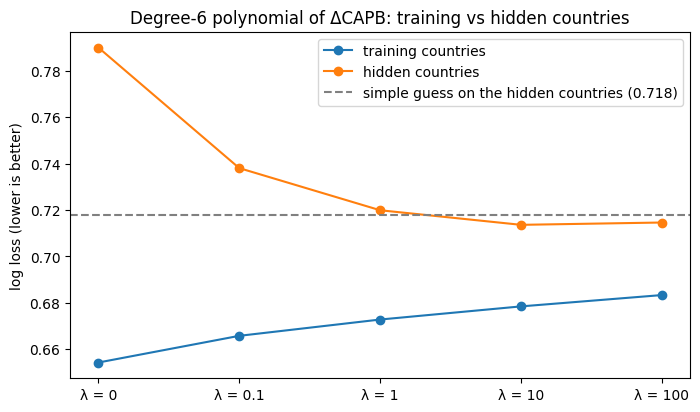

       training log loss  hidden log loss
0.0                0.654            0.790
0.1                0.666            0.738
1.0                0.673            0.720
10.0               0.679            0.714
100.0              0.683            0.715


In [ ]:
# The overfitting chart
baseline = log_loss(y_test, np.full(len(y_test), y_train.mean()))
pos = np.arange(len(LAMBDAS))
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(pos, [res[l][0] for l in LAMBDAS], "o-", label="training countries")
ax.plot(pos, [res[l][1] for l in LAMBDAS], "o-", label="hidden countries")
ax.axhline(baseline, ls="--", color="grey", label=f"simple guess on the hidden countries ({baseline:.3f})")
ax.set_xticks(pos); ax.set_xticklabels([f"λ = {l:g}" for l in LAMBDAS])
ax.set_ylabel("log loss (lower is better)")
ax.set_title("Degree-6 polynomial of ΔCAPB: training vs hidden countries")
ax.legend(); plt.show()
print(pd.DataFrame(res, index=["training log loss", "hidden log loss"]).T.round(3))

**Compare with your predictions.**
- Where is the gap between the two lines largest, and where is it smallest?
- Does any λ get below the grey line? What does that say about predicting weak growth from ΔCAPB alone?
- Look at the largest ΔCAPB in the training countries (`train[DCAPB].max()` and which episode it is). How might one episode dominate x⁶?
- Stopping gradient descent after 10,000 steps kept λ = 0 far from scikit-learn's finished result. Why does stopping early act a bit like regularization?

Learning log – ML03b (5 Nov 2026)
- My own gradient descent gives exactly scikit-learn's weights; the cost starts at log(2) = 0.693 (a coin flip) and only falls to 0.634.
- The decision boundary can't separate weak from not-weak episodes: the two groups overlap almost completely.
- Without λ, a degree-6 model memorises the training countries (hidden loss 0.79, worse than guessing); λ = 10 fixes that but only reaches 0.714 vs 0.718.